# Taller final de minería de datos
## Segmentación de clientes con K-Means

Se utiliza el dataset [Mall Customers](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python) para agrupar clientes según su ingreso anual y su puntuación de gasto.

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

variables = ["Annual Income (k$)", "Spending Score (1-100)"]
numericas = ["Age"] + variables
sns.set_theme(style="whitegrid")

## Parte 1. Exploración de datos

Se revisan las variables, las estadísticas principales y los posibles valores atípicos. El ingreso anual está en miles de dólares y el Spending Score es una puntuación entre 1 y 100.

In [2]:
if Path("Mall_Customers.csv").exists():
    datos = pd.read_csv("Mall_Customers.csv")
else:
    datos = pd.read_csv("https://raw.githubusercontent.com/Jacklb19/K-means/main/Mall_Customers.csv")

display(datos.head())
print("Filas y columnas:", datos.shape)

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


Filas y columnas: (200, 5)


In [3]:
datos.info()
display(datos.isnull().sum().to_frame("Datos faltantes"))
print("Filas duplicadas:", datos.duplicated().sum())
display(datos[numericas].describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


,Datos faltantes
CustomerID,0
Gender,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0


Filas duplicadas: 0


,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000
mean,38.850000,60.560000,50.200000
std,13.969007,26.264721,25.823522
min,18.000000,15.000000,1.000000
25%,28.750000,41.500000,34.750000
50%,36.000000,61.500000,50.000000
75%,49.000000,78.000000,73.000000
max,70.000000,137.000000,99.000000


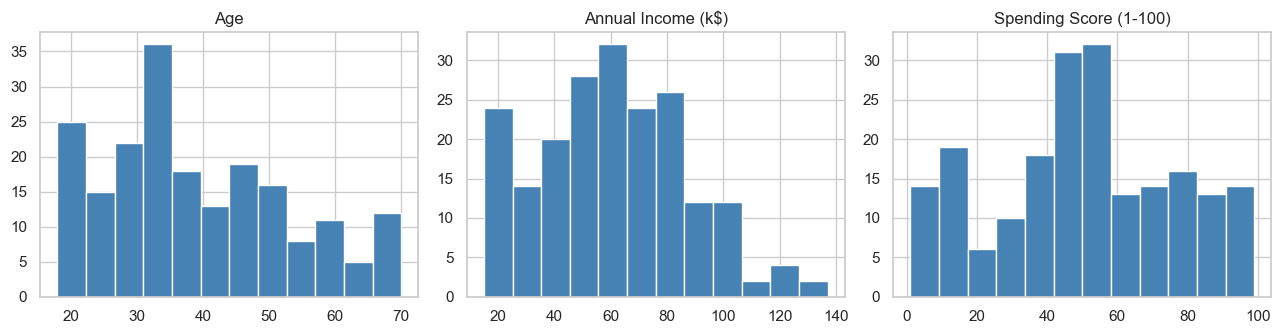

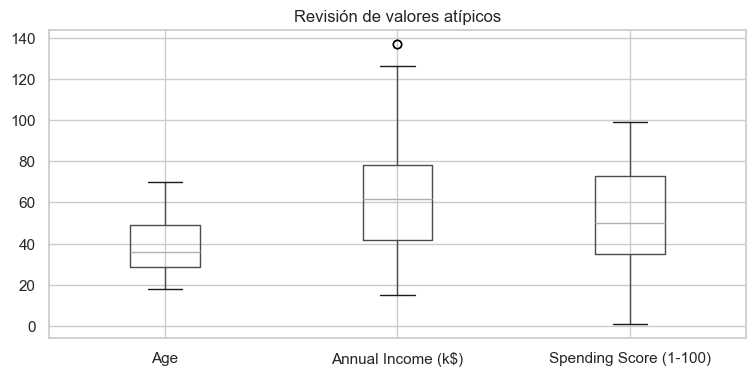

In [4]:
datos[numericas].hist(bins=12, figsize=(13, 3.5), layout=(1, 3), color="steelblue")
plt.tight_layout()
plt.show()

datos[numericas].boxplot(figsize=(9, 4))
plt.title("Revisión de valores atípicos")
plt.show()

In [5]:
for columna in numericas:
    q1 = datos[columna].quantile(0.25)
    q3 = datos[columna].quantile(0.75)
    iqr = q3 - q1
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr
    atipicos = datos[(datos[columna] < limite_inferior) | (datos[columna] > limite_superior)]
    print(columna, "- Valores atípicos:", len(atipicos))
    if len(atipicos) > 0:
        display(atipicos[["CustomerID", columna]])

Age - Valores atípicos: 0
Annual Income (k$) - Valores atípicos: 2


,CustomerID,Annual Income (k$)
198,199,137
199,200,137


Spending Score (1-100) - Valores atípicos: 0


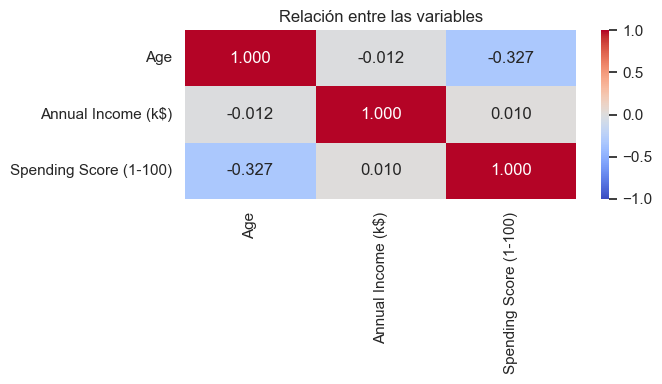

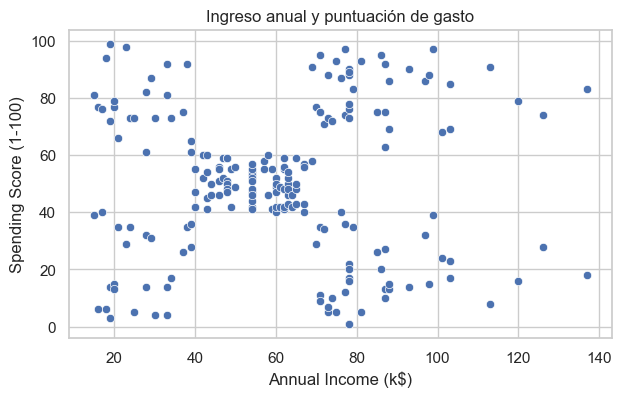

In [6]:
correlaciones = datos[numericas].corr()
plt.figure(figsize=(7, 4))
sns.heatmap(correlaciones, annot=True, fmt=".3f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Relación entre las variables")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
sns.scatterplot(data=datos, x=variables[0], y=variables[1])
plt.title("Ingreso anual y puntuación de gasto")
plt.show()

#### ¿Qué variables son más adecuadas para segmentar clientes?

Para este trabajo se eligieron **el ingreso anual y la puntuación de gasto**. El ingreso permite conocer el nivel económico del cliente y la puntuación ayuda a comparar su comportamiento de compra. Al combinarlos se pueden encontrar grupos útiles para plantear estrategias de marketing.

No se utiliza **CustomerID**, porque es un identificador y no una característica del cliente. La **edad** se revisa para describir los grupos. El **género** no se incluye en el modelo, ya que no es necesario para la segmentación que se busca y necesitaría un tratamiento diferente por ser una categoría.

#### ¿Se identifican valores atípicos?

Sí. Con la regla del rango intercuartílico, el límite superior del ingreso es **132,75 mil dólares**. Los clientes **199, 200**, con ingresos de **137 mil dólares**, quedan por encima de ese límite. No aparecen valores atípicos en edad ni en puntuación de gasto con esta regla.

Se decidió conservarlos porque un ingreso alto no significa que el dato esté mal. También se comprobó que no hay datos faltantes ni filas duplicadas.

#### ¿Qué tipo de relaciones se observan entre las variables?

Entre ingreso y puntuación de gasto la correlación es de **0.010**, muy cercana a cero. Esto indica que tener más ingresos no siempre significa tener una puntuación de gasto más alta. En la gráfica se observan clientes con ingresos similares, pero con comportamientos de gasto diferentes.

La edad y la puntuación de gasto tienen una relación negativa de **-0.327**: en esta muestra, los clientes más jóvenes tienden a tener una puntuación algo mayor. La relación entre edad e ingreso es casi nula. Son tendencias de los datos y no permiten asegurar que una variable sea la causa de la otra.

## Parte 2. Preprocesamiento

Se usa `StandardScaler` para poner el ingreso y la puntuación de gasto en una escala comparable.

In [7]:
X = datos[variables]
escalador = StandardScaler()
X_scaled = escalador.fit_transform(X)

display(pd.DataFrame(X_scaled, columns=variables).head())

,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980


#### ¿Por qué es necesario escalar las variables en el algoritmo K-Means?

K-Means forma los grupos usando la distancia entre los clientes y los centros de los grupos. Si una variable maneja números mucho más grandes que otra, puede pesar más en el resultado solo por su escala.

Por eso se usa `StandardScaler`: permite comparar las dos variables en condiciones más parecidas. Esto no significa que todos los valores queden entre 0 y 1. Además, al ingresar un nuevo cliente se debe usar el mismo escalador del entrenamiento, sin volver a ajustarlo.

## Parte 3. Método del codo

Se prueba K desde 1 hasta 10 y se observa dónde la curva de inercia empieza a aplanarse.

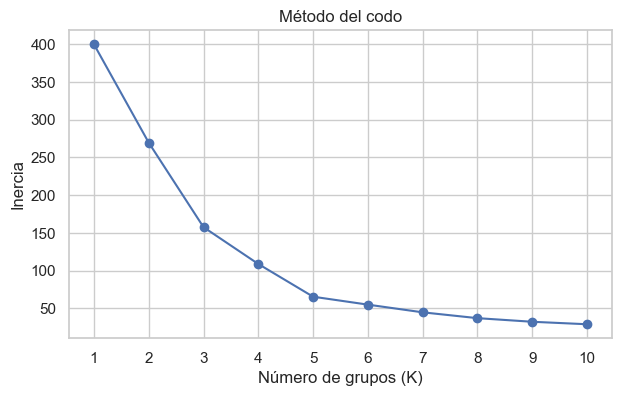

In [8]:
inercias = []
for k in range(1, 11):
    modelo = KMeans(n_clusters=k, random_state=42, n_init=30)
    modelo.fit(X_scaled)
    inercias.append(modelo.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(range(1, 11), inercias, "o-")
plt.xlabel("Número de grupos (K)")
plt.ylabel("Inercia")
plt.title("Método del codo")
plt.xticks(range(1, 11))
plt.show()

#### ¿Por qué valores cercanos a cero indican mejor ajuste?

En este caso se habla de la **inercia**. Cuando es pequeña, los clientes están más cerca del centro de su grupo, por lo que los grupos son más compactos.

Sin embargo, no se debe elegir el modelo solamente porque su inercia sea la más baja. Al aumentar K, la inercia sigue bajando; si se hiciera un grupo por cliente, podría llegar a cero y la segmentación dejaría de ser útil. Por eso se busca un equilibrio con el método del codo y se revisa también la silueta.

#### ¿Cómo se identifica el punto óptimo de K?

El punto se identifica donde la curva empieza a aplanarse. En este caso se observa un codo en **K = 5**. Pasar de cuatro a cinco grupos reduce la inercia un **39.8%**, mientras que pasar de cinco a seis la reduce un **16.0%**.

Esto hace que cinco grupos sea una opción razonable: todavía mejora bastante la agrupación y no agrega tantos segmentos. La elección se confirma con el coeficiente de silueta.

## Parte 4. Coeficiente de silueta

Se calcula la silueta para K desde 2 hasta 10. No se calcula para K=1 porque se necesitan al menos dos grupos.

,K,Inercia,Silueta
0,1,400.0000,NaN
1,2,269.6910,0.3213
2,3,157.7040,0.4666
3,4,108.9213,0.4939
4,5,65.5684,0.5547
5,6,55.0573,0.5399
6,7,44.8648,0.5281
7,8,37.1481,0.4567
8,9,32.3602,0.4565
9,10,29.0762,0.4494


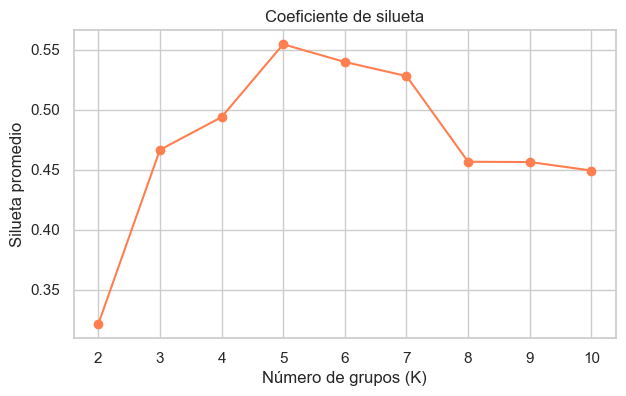

In [9]:
siluetas = []
for k in range(2, 11):
    modelo = KMeans(n_clusters=k, random_state=42, n_init=30)
    grupos = modelo.fit_predict(X_scaled)
    siluetas.append(silhouette_score(X_scaled, grupos))

resultados = pd.DataFrame({
    "K": range(1, 11),
    "Inercia": inercias,
    "Silueta": [np.nan] + siluetas
})
display(resultados.round(4))

plt.figure(figsize=(7, 4))
plt.plot(range(2, 11), siluetas, "o-", color="coral")
plt.xlabel("Número de grupos (K)")
plt.ylabel("Silueta promedio")
plt.title("Coeficiente de silueta")
plt.xticks(range(2, 11))
plt.show()

#### ¿Qué mide el coeficiente de silueta?

Mide qué tan parecido es un cliente a los demás de su grupo, comparado con los clientes del grupo vecino más cercano. Así permite revisar si los grupos están bien separados. Un promedio más alto suele indicar una mejor agrupación, aunque no es un porcentaje de aciertos.

#### ¿Qué significa un valor cercano a 1?

Un valor cercano a **1** significa que el cliente está bien ubicado: se parece más a los de su propio grupo que a los de otros grupos. Si el promedio se acerca a 1, los grupos están bien definidos y separados.

#### ¿Qué implica un valor cercano a 0 o negativo?

Un valor cercano a **0** indica que el cliente está entre dos grupos y no hay una diferencia clara para asignarlo a uno de ellos. Un valor **negativo** significa que se parece más a otro grupo que al que se le asignó. Esos casos conviene revisarlos, aunque no necesariamente sean datos incorrectos.

#### ¿Coincide el valor óptimo de K con el método del codo? Justifique.

**Sí, ambos métodos coinciden en K = 5.** En el codo se identifica ese punto y la silueta obtiene su valor más alto, **0.5547**, con cinco grupos entre los valores evaluados.

Por eso se seleccionan cinco clusters. El resultado muestra una separación útil, aunque no perfecta, y los grupos se pueden interpretar según el ingreso y la puntuación de gasto.

## Parte 5. Modelo K-Means

Se entrena el modelo con el K seleccionado, se asigna un grupo a cada cliente y se obtienen los centroides en las unidades originales.

In [10]:
k_elegido = int(resultados.loc[resultados["Silueta"].idxmax(), "K"])
modelo = KMeans(n_clusters=k_elegido, random_state=42, n_init=30)
datos["Cluster"] = modelo.fit_predict(X_scaled)

centroides = pd.DataFrame(
    escalador.inverse_transform(modelo.cluster_centers_),
    columns=variables
)
centroides.index.name = "Cluster"
display(centroides.round(2))

,Annual Income (k$),Spending Score (1-100)
Cluster,,
0,55.30,49.52
1,86.54,82.13
2,25.73,79.36
3,88.20,17.11
4,26.30,20.91


In [11]:
perfiles = {
    0: "Promedio",
    1: "Alto valor relativo",
    2: "Gasto alto e ingreso bajo",
    3: "Potencial de crecimiento",
    4: "Valor actual bajo"
}
datos["Perfil"] = datos["Cluster"].map(perfiles)

resumen = datos.groupby("Cluster").agg(
    Clientes=("CustomerID", "count"),
    Edad_media=("Age", "mean"),
    Ingreso_medio=(variables[0], "mean"),
    Score_medio=(variables[1], "mean")
)
resumen["Porcentaje"] = resumen["Clientes"] / len(datos) * 100
resumen["Perfil"] = resumen.index.map(perfiles)
display(resumen.round(2))

,Clientes,Edad_media,Ingreso_medio,Score_medio,Porcentaje,Perfil
Cluster,,,,,,
0,81,42.72,55.30,49.52,40.5,Promedio
1,39,32.69,86.54,82.13,19.5,Alto valor relativo
2,22,25.27,25.73,79.36,11.0,Gasto alto e ingreso bajo
3,35,41.11,88.20,17.11,17.5,Potencial de crecimiento
4,23,45.22,26.30,20.91,11.5,Valor actual bajo


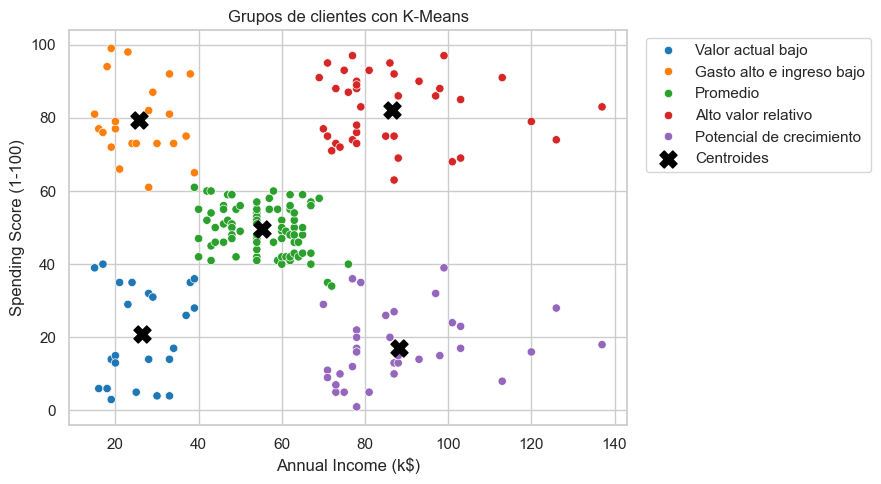

In [12]:
plt.figure(figsize=(9, 5))
sns.scatterplot(data=datos, x=variables[0], y=variables[1], hue="Perfil", palette="tab10")
plt.scatter(centroides[variables[0]], centroides[variables[1]],
            color="black", marker="X", s=150, label="Centroides")
plt.title("Grupos de clientes con K-Means")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

#### ¿Qué representa cada cluster?

**Cluster 0: Promedio.** 81 clientes (40.5%); ingreso medio **55.30 mil dólares**, puntuación media **49.52** y edad media **42.7 años**.

**Cluster 1: Alto valor relativo.** 39 clientes (19.5%); ingreso medio **86.54 mil dólares**, puntuación media **82.13** y edad media **32.7 años**.

**Cluster 2: Gasto alto e ingreso bajo.** 22 clientes (11.0%); ingreso medio **25.73 mil dólares**, puntuación media **79.36** y edad media **25.3 años**.

**Cluster 3: Potencial de crecimiento.** 35 clientes (17.5%); ingreso medio **88.20 mil dólares**, puntuación media **17.11** y edad media **41.1 años**.

**Cluster 4: Valor actual bajo.** 23 clientes (11.5%); ingreso medio **26.30 mil dólares**, puntuación media **20.91** y edad media **45.2 años**.

#### ¿Qué diferencias existen entre los grupos obtenidos?

La diferencia principal está en la combinación de ingreso y gasto. Hay un grupo con valores intermedios y otros cuatro que combinan ingresos altos o bajos con puntuaciones de gasto altas o bajas.

Esto muestra que no todos los clientes con ingresos altos gastan igual y que también hay clientes con ingresos bajos y una puntuación de gasto alta. La edad ayuda a describirlos: por ejemplo, el grupo de ingreso bajo y gasto alto es más joven en promedio. Aun así, la edad no se usó para asignar los cinco grupos del modelo final.

## Parte 6. Interpretación de negocio

Los nombres de los perfiles se asignan según el ingreso y la puntuación de gasto de cada grupo. Hablar de valor alto o bajo no significa conocer las ganancias reales, porque el dataset no contiene esa información.

#### ¿Qué estrategias de marketing se podrían aplicar a cada grupo?

**Promedio (cluster 0):** Usar programas de puntos, paquetes de productos y promociones para aumentar la frecuencia de compra. Revisar si regresan más seguido y si aumenta el valor de sus compras.

**Alto valor relativo (cluster 1):** Ofrecer beneficios de fidelización, atención personalizada y acceso anticipado a productos. Revisar si estos clientes siguen comprando y responden a las ofertas.

**Gasto alto e ingreso bajo (cluster 2):** Ofrecer beneficios de fidelización y promociones que les resulten útiles. Buscar que sigan comprando sin depender de descuentos constantes.

**Potencial de crecimiento (cluster 3):** Investigar por qué compran poco y probar recomendaciones o promociones de reactivación. Comparar sus compras antes y después de la campaña.

**Valor actual bajo (cluster 4):** Utilizar promociones sencillas y comunicaciones de bajo costo. Evaluar su respuesta antes de invertir más en campañas para este grupo.

Estas estrategias son propuestas basadas en los perfiles. Para saber si funcionan, se pueden comparar campañas con un grupo que reciba la oferta y otro que no, revisando compras, frecuencia y ganancias reales.

#### ¿Qué segmento representa mayor oportunidad de crecimiento?

El grupo con mayor oportunidad de crecimiento es el de **ingreso alto y puntuación de gasto baja**, llamado **Potencial de crecimiento**. Tiene **35 clientes**, que representan el **17.5%** de la muestra. Su ingreso promedio es de **88.20 mil dólares** y su puntuación de gasto promedio es de **17.11**.

Podría ser una oportunidad porque sus ingresos son altos, pero su participación de gasto es baja. Se podrían investigar sus preferencias y probar campañas que les den más motivos para comprar. Esto no asegura que vayan a gastar más; habría que comprobarlo con los resultados de las campañas y con datos reales de ventas.

## Parte 7. Aplicación en Streamlit

La aplicación está en el archivo [app.py](https://github.com/Jacklb19/K-means/blob/main/app.py). Permite ver el método del codo y los clusters, ingresar un nuevo cliente y asignarlo automáticamente a un grupo.